### 선형 회귀 실습 문제

# Tips Dataset
: 레스토랑의 총 식사 금액을 이용해 손님이 지불할 팁 금액을 예측하는 선형 회귀 모델 구현.

#### Step1. 데이터 불러오기 및 전처리

**사용 데이터: Tips Dataset**

- 데이터: 244개
- 입력 특징: 1개 (총 식사 금액 (`total_bill`))
- 정답: 팁 금액(`tip`)

| 열 이름 | 의미 | 설명 |
|:---:|:---:|:---|
| `total_bill` | 총 식사 금액 | 식사에 청구된 총 금액 |
| `tip` | 팁 금액 | 종업원에게 지불한 팁 |
| `sex` | 성별 | 계산한 손님의 성별 |
| `smoker` | 흡연 여부 | 흡연자 여부 |
| `day` | 요일 | 식사한 요일 |
| `time` | 식사 시간 | Lunch 또는 Dinner |
| `size` | 인원수 | 테이블의 손님 수 |

**실습 조건**
- 입력값(X): `total_bill`
- 정답(y): `tip`
- 결측치가 있는지 확인하고, 필요한 경우 처리한다.
- 학습 데이터와 테스트 데이터를 8:2 비율로 분리한다.
- 입력값은 학습 데이터의 평균과 표준편차를 이용해 표준화한다.
- `total_bill`과 `tip`의 관계를 산점도로 먼저 확인한다.

In [12]:
import pandas as pd
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)

In [13]:
# Tips 데이터 불러오기
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df = pd.read_csv(url)

print(df.head())
print("데이터 크기:", df.shape)
print("\n결측치 개수:")
print(df.isnull().sum())

# 이번 실습에 필요한 두 열만 사용
df = df[["total_bill", "tip"]].dropna().copy()

X = torch.tensor(df[["total_bill"]].values, dtype=torch.float32)
y = torch.tensor(df[["tip"]].values, dtype=torch.float32)

# 학습/테스트 데이터 8:2 분리
indices = torch.randperm(len(X))
split = int(len(X) * 0.8)

train_indices = indices[:split]
test_indices = indices[split:]

X_train = X[train_indices]
X_test = X[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

# 학습 데이터의 평균과 표준편차로 입력값 표준화
mean = X_train.mean(dim=0)
std = X_train.std(dim=0).clamp(min=1e-8)

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

print("\nX_train:", X_train_scaled.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test_scaled.shape)
print("y_test:", y_test.shape)

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
데이터 크기: (244, 7)

결측치 개수:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

X_train: torch.Size([195, 1])
y_train: torch.Size([195, 1])
X_test: torch.Size([49, 1])
y_test: torch.Size([49, 1])


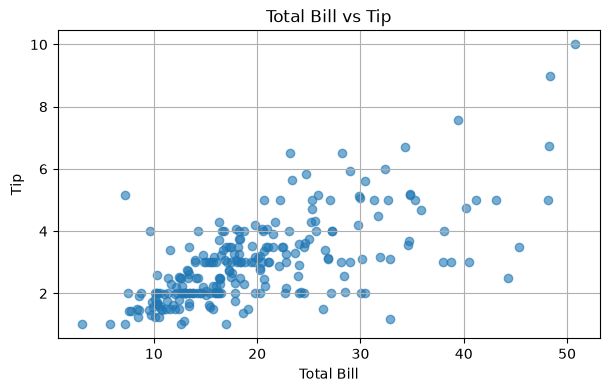

In [14]:
# 전체 데이터의 관계 확인
plt.figure(figsize=(7, 4))
plt.scatter(X.numpy(), y.numpy(), alpha=0.6)
plt.xlabel("Total Bill")
plt.ylabel("Tip")
plt.title("Total Bill vs Tip")
plt.grid(True)
plt.show()

#### Step2. 모델 만들기

- 입력 노드: 1개 (`total_bill`)
- 출력 노드: 1개 (`tip`)
- 활성화 함수: 사용하지 않음
- 모델: `nn.Linear`

In [15]:
model = nn.Linear(1, 1)

# 임의의 데이터 5개로 출력 형태 확인
sample = torch.randn(5, 1)
output = model(sample)

print("출력 shape:", output.shape)
print(output)

출력 shape: torch.Size([5, 1])
tensor([[-0.3866],
        [-0.6517],
        [ 0.0261],
        [-0.2228],
        [-0.5308]], grad_fn=<AddmmBackward0>)


#### STEP 3. 모델 학습시키기

- Optimizer: SGD
- Loss function: MSELoss
- 학습률(LR): 0.01부터 시작
- Epoch: 200
- Batch size: 32

Epoch:   1, Train MSE: 12.5058
Epoch:  20, Train MSE: 1.1253
Epoch:  40, Train MSE: 1.0750
Epoch:  60, Train MSE: 1.0744
Epoch:  80, Train MSE: 1.0755
Epoch: 100, Train MSE: 1.0766
Epoch: 120, Train MSE: 1.0783
Epoch: 140, Train MSE: 1.0749
Epoch: 160, Train MSE: 1.0756
Epoch: 180, Train MSE: 1.0751
Epoch: 200, Train MSE: 1.0744


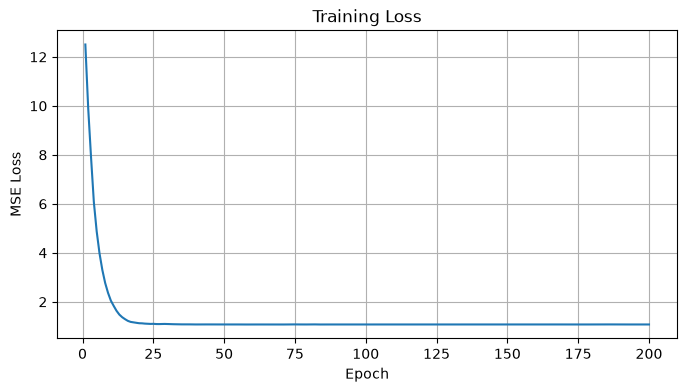

In [16]:
BATCH_SIZE = 32
LR = 0.01
EPOCH = 200

train_DS = TensorDataset(X_train_scaled, y_train)
train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)

N = len(train_DL.dataset)

optimizer = optim.SGD(model.parameters(), lr=LR)
criterion = nn.MSELoss()

loss_history = []

model.train()
for ep in range(EPOCH):
    running_loss = 0.0

    for x_batch, y_batch in train_DL:
        y_hat = model(x_batch)
        loss = criterion(y_hat, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * x_batch.shape[0]

    epoch_loss = running_loss / N
    loss_history.append(epoch_loss)

    if (ep + 1) % 20 == 0 or ep == 0:
        print(f"Epoch: {ep+1:3d}, Train MSE: {epoch_loss:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCH + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss")
plt.grid(True)
plt.show()

#### Step4. 모델 테스트하기


In [17]:
model.eval()

with torch.no_grad():
    y_pred = model(X_test_scaled)

mse = criterion(y_pred, y_test).item()
rmse = np.sqrt(mse)
mae = torch.mean(torch.abs(y_pred - y_test)).item()

print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")

MSE:  0.8846
RMSE: 0.9406
MAE:  0.6259


#### Step5. 테스트 결과 시각화

**문제**
- 첫 번째 그래프: 테스트 데이터의 실제 산점도와 모델의 예측 회귀선을 함께 표시.
- 두 번째 그래프: 실제 팁 금액을 x축, 예측 팁 금액을 y축으로 하는 산점도를 작성.
- 두 번째 그래프에 완벽한 예측을 나타내는 기준선(y=x)을 추가.
- 그래프의 축 이름과 제목을 적절히 표시.

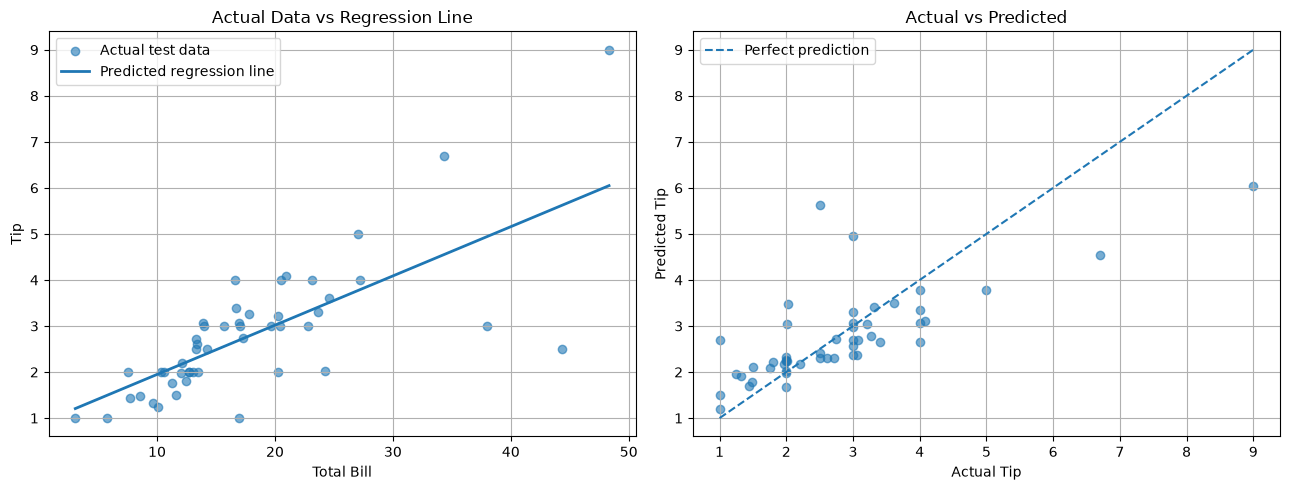

In [18]:
# 테스트 데이터의 원래 total_bill 값 기준으로 정렬
sort_idx = torch.argsort(X_test.squeeze())
X_test_sorted = X_test[sort_idx]
X_test_scaled_sorted = X_test_scaled[sort_idx]
y_test_sorted = y_test[sort_idx]

model.eval()
with torch.no_grad():
    y_pred_sorted = model(X_test_scaled_sorted)
    y_pred = model(X_test_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 실제 테스트 데이터와 예측 회귀선
axes[0].scatter(X_test.numpy(), y_test.numpy(),
                alpha=0.6, label="Actual test data")
axes[0].plot(X_test_sorted.numpy(), y_pred_sorted.numpy(),
             linewidth=2, label="Predicted regression line")
axes[0].set_xlabel("Total Bill")
axes[0].set_ylabel("Tip")
axes[0].set_title("Actual Data vs Regression Line")
axes[0].legend()
axes[0].grid(True)

# 실제값과 예측값 비교
axes[1].scatter(y_test.numpy(), y_pred.numpy(), alpha=0.6)

min_val = min(y_test.min().item(), y_pred.min().item())
max_val = max(y_test.max().item(), y_pred.max().item())
axes[1].plot([min_val, max_val], [min_val, max_val],
             linestyle="--", label="Perfect prediction")

axes[1].set_xlabel("Actual Tip")
axes[1].set_ylabel("Predicted Tip")
axes[1].set_title("Actual vs Predicted")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

#### STEP 6. 파라미터 개수 확인

In [19]:
weight_count = model.weight.numel()
bias_count = model.bias.numel()

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"가중치(weight) 개수: {weight_count}")
print(f"편향(bias) 개수: {bias_count}")
print(f"전체 학습 가능 파라미터: {total_params}")

가중치(weight) 개수: 1
편향(bias) 개수: 1
전체 학습 가능 파라미터: 2
